In [4]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
from peak_significance import*

In [3]:
!python spc_to_csv-new.py 45HCobalt60.Spc

Wrote 8192 channels to 45HCobalt60.csv
live time 162570 s, real time 162819 s, total counts 7,061


In [5]:
!python spc_to_csv-new.py Co60-Pb-max.Spc

Wrote 8192 channels to Co60-Pb-max.csv
live time 214626 s, real time 216000 s, total counts 113,324


In [6]:
ch_l, n_l, L_l = load_run("Co60-Pb-max.csv")

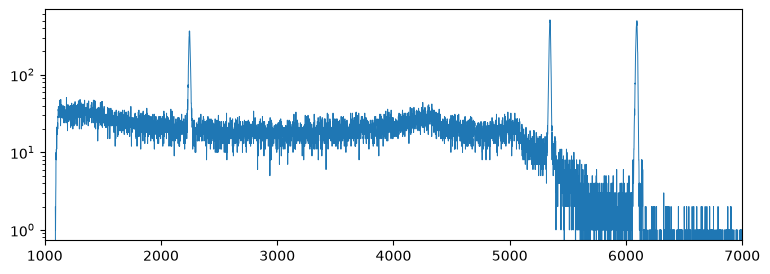

In [8]:
plt.figure(figsize=(9,3))
plt.semilogy(ch_l, n_l, lw=0.7); plt.xlim(1000, 7000)
plt.show()

In [19]:
coeffs = 31.7144, 0.215104
check_lines(ch_l, n_l, coeffs)

m, c, table, ch_of = run_calibration(ch_l, n_l, coeffs, energies=(511,1173.23, 1332.49), verbose=True)
mu_l = ch_of(511.0)                      # 511 keV channel for THIS run

print(mu_l)

 1173.23 keV: predicted ch   5306.8, strongest bin     5321, offset +14.2 ch
 1332.49 keV: predicted ch   6047.2, strongest bin     6060, offset +12.8 ch
  E_keV  centroid  centroid_err  fwhm_ch  resid_ch
 511.00   2245.38          0.10    15.17     -0.01
1173.23   5346.00          0.08    14.36      0.08
1332.49   6091.51          0.08    15.89     -0.06
  channel = 4.6820 * E + -147.09   (channel of 0 keV: -147.1)
2245.3896606938292


In [22]:
mu = channel_of(511.0, coeffs)
# width from your resolution fit
fwhm_keV = np.sqrt(21.746 + -0.0097 * 511.0)  # used data from resolution results .
slope = coeffs[1]                       # keV per channel (linear calibration)
sigma = fwhm_keV / slope / 2.35      # in channels
print(mu, sigma)

2228.1575423980958 8.088665888684174


In [23]:
fl = peak_fit(ch_l, n_l, mu_l, sigma)
print(f"with lead and coincidence: area {fl['area']:.0f} +/- {fl['area_err']:.0f}, Z = {fl['Z']:.1f} sigma")

with lead and coincidence: area 5450 +/- 51, Z = 106.7 sigma
